# Customer Clustring (K-Meaans)

## Pakcges & Libs

In [149]:
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt 

## Reading Data

In [136]:
df = pd.read_csv("1632560262896716.csv")
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [137]:
df.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


## Pre-Prosessing

In [138]:
le_sex = LabelEncoder()
le_sex.fit(['Female','Male'])
df["Gender"] = le_sex.transform(df["Gender"]) 
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,1,19,15,39
1,2,1,21,15,81
2,3,0,20,16,6
3,4,0,23,16,77
4,5,0,31,17,40


Gender in data set is a categorial variable. The k-means model isn't directly applicable to categorial variables.

In [139]:
df_ = df.drop("Gender", axis=1)
df_.head()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
0,1,19,15,39
1,2,21,15,81
2,3,20,16,6
3,4,23,16,77
4,5,31,17,40


In [140]:
X = df_.values[:, 1:]
clus_df = StandardScaler().fit(X)
clus_df = clus_df.transform(X)
clus_df[:5]

array([[-1.42456879, -1.73899919, -0.43480148],
       [-1.28103541, -1.73899919,  1.19570407],
       [-1.3528021 , -1.70082976, -1.71591298],
       [-1.13750203, -1.70082976,  1.04041783],
       [-0.56336851, -1.66266033, -0.39597992]])

## Modeling

### Selecting number of clusters

In [141]:
range_n_clusters = np.arange(2, 14)

for n_clusters in range_n_clusters:
    clusterer = KMeans(init="k-means++", n_clusters=n_clusters)
    cluster_labels = clusterer.fit_predict(clus_df)

    silhouette_avg = silhouette_score(clus_df, cluster_labels)
    print("For n_clusters =", n_clusters,
            "The average silhouette_score is :", silhouette_avg,
    )

For n_clusters = 2 The average silhouette_score is : 0.33547192894004574
For n_clusters = 3 The average silhouette_score is : 0.3579234303882264
For n_clusters = 4 The average silhouette_score is : 0.4039582785148566
For n_clusters = 5 The average silhouette_score is : 0.41664341513732767
For n_clusters = 6 The average silhouette_score is : 0.39954904069708375
For n_clusters = 7 The average silhouette_score is : 0.4180766295787896
For n_clusters = 8 The average silhouette_score is : 0.4121174520002582
For n_clusters = 9 The average silhouette_score is : 0.3688930948870177
For n_clusters = 10 The average silhouette_score is : 0.38170485327301046
For n_clusters = 11 The average silhouette_score is : 0.40864871657943896
For n_clusters = 12 The average silhouette_score is : 0.37291990461651975
For n_clusters = 13 The average silhouette_score is : 0.3629591520303428


so best number of clusters for this data set is 6: `n_cluster = 6`

### Creating Clusters

In [142]:
n = 6
k_means = KMeans(init = "k-means++", n_clusters=n, random_state=13)
k_means.fit(clus_df)
labels = k_means.labels_
labels

array([4, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4,
       2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 1, 4, 2, 5,
       2, 4, 1, 5, 5, 5, 1, 5, 5, 1, 1, 1, 1, 1, 5, 1, 1, 5, 1, 1, 1, 5,
       1, 1, 5, 5, 1, 1, 1, 1, 1, 5, 1, 5, 5, 1, 1, 5, 1, 1, 5, 1, 1, 5,
       5, 1, 1, 5, 1, 5, 5, 5, 1, 5, 1, 5, 5, 1, 1, 5, 1, 5, 1, 1, 1, 1,
       1, 5, 5, 5, 5, 5, 1, 1, 1, 1, 5, 5, 5, 0, 5, 0, 3, 0, 3, 0, 3, 0,
       5, 0, 3, 0, 3, 0, 3, 0, 3, 0, 5, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0,
       3, 0, 3, 0, 3, 0, 1, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0,
       3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0, 3, 0,
       3, 0])

## Insights

In [143]:
df["Cust Clus"] = labels
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100),Cust Clus
0,1,1,19,15,39,4
1,2,1,21,15,81,4
2,3,0,20,16,6,2
3,4,0,23,16,77,4
4,5,0,31,17,40,2


In [145]:
df.groupby("Cust Clus").mean()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
Cust Clus,,,,,
0,162.000000,0.461538,32.692308,86.538462,82.128205
1,83.777778,0.422222,56.333333,54.266667,49.066667
2,23.190476,0.380952,45.523810,26.285714,19.380952
3,164.529412,0.588235,41.264706,88.500000,16.764706
4,22.130435,0.434783,25.000000,25.260870,77.608696
5,90.052632,0.342105,27.000000,56.657895,49.131579


## Visulization

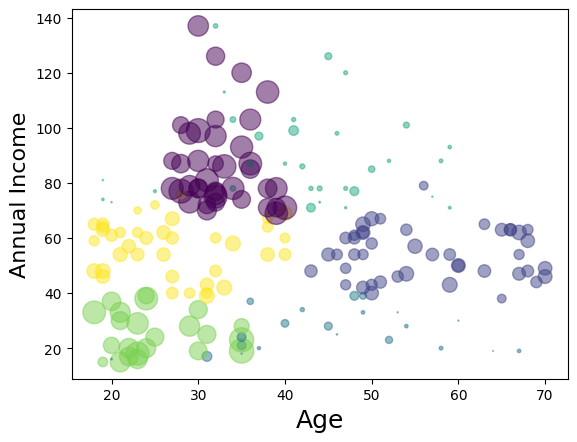

In [154]:
area = (np.pi * (X[:, 2])**2) * 0.01
plt.scatter(X[:, 0], X[:, 1], s=area, c=labels.astype(float), alpha=0.5)
plt.xlabel("Age", fontsize=18)
plt.ylabel("Annual Income", fontsize=16)

plt.show()

# Author: Sadra Gholami